# CSE 242 Assignment 2

3 questions, 100 pts

Name: Letian    Student ID: 2151132

## Instruction 

- Submit your assignments onto **Canvas** by the due date. Upload a <code>zip</code> file containing:

    (1) The saved/latest <code>.ipynb</code> file.

    (2) Also save your file into a pdf version, if error appears, save an html version instead (easy to grade for written questions).
    
    (3) All other materials to make your <code>.ipynb</code> file runnable.
    
    **For assignment related questions, please reach TA or grader through EdDiscussion.**
    
- This is an **individual** assignment. All help from others (from the web, books other than text, genAI, or people other than the TA or instructor) must be clearly acknowledged. 
- Most coding parts can be finished with only 1-2 lines of codes.
- Make sure you have installed required packages: <code>scikit-learn</code>.
- Double click to edit each markdown cell.

## Objective 

- **Task 1:** Maximum likelihood estiamtion (math)
- **Task 2:** Linear Regression (with Scikit-learn)
- **Task 3:** Principle Component Analysis (with Scikit-learn)

# Question 1 (Maximum likelihood estiamtion and Posterior, 20 pts) 

Assume we have a coin that has some unknown probability $h$ of coming up heads (and probability $1-h$ of coming up tails). If the coin is flipped five times getting three heads and two tails ($\mathbf{HHHTT}$) then:

(a -- 10pts) What is the maximum likelihood estimate for $h$?

(b -- 10pts) Assume that (before flipping the coin) we have a prior density $p(h)$ for the various values of $h\in [0,1]$. Give the formula for the posterior probability density $p(h \mid \mathbf{HHHTT})$ as a function of the prior $p(h)$.

For Question 1(b), the solution is acceptable if the formula contains an integral.

**(a)**

$\displaystyle L(h)=h^3(1-h)^2,\quad \ell'(h)=\frac3h-\frac2{1-h}=0\Rightarrow\hat h=\frac35.$

$\ell''<0$; endpoints give 0.

**(b)**

$\displaystyle p(h\mid\mathbf{HHHTT})=\frac{h^3(1-h)^2p(h)}{\int_0^1t^3(1-t)^2p(t)\,dt},\quad 0\le h\le1.$

0 elsewhere; denominator > 0.

# Question 2 (Linear Regression, 40 pts)
In this question, you will be using **Scikit-learn** to empirically apply the Linear Regression model. We will adopt an advertisement dataset **Advertising.csv** from Kaggle. 

### Reading data using Pandas

In [1]:
import numpy as np
import pandas as pd
data = pd.read_csv('Advertising.csv', index_col=0)
data.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [2]:
data.shape

(200, 4)

### Features and responses

What are the features?
- **TV:** advertising dollars spent on TV for a single product in a given market (in thousands of dollars)
- **Radio:** advertising dollars spent on Radio
- **Newspaper:** advertising dollars spent on Newspaper

What is the response?
- **Sales:** sales of a single product in a given market (in thousands of items)

What else do we know?
- There are 200 **observations**, and each observation (each row) is a single market.
- **Your main task**: predict the sales of a single product in a given market.
- Since the response variable is continuous, this is a **regression** problem.

### Linear regression

**Pros:** fast, no tuning required, highly interpretable

**Cons:** adopting the linear regression is unlikely to always generate the best predictive accuracy, since Linear Regression presumes a linear relationship between the features and response. This assumption may not always make sense. (But if one can _transform_ the features so that do have a linear relationship, sometimes progress can be made, for example by taking logs.)

**Expression:**

- $y$: the response
- $\beta_0$: the intercept
- $\beta_1$: the coefficient for $x_1$ (the first feature)
- $\beta_i$ is the coefficient for $x_i$ (the ith feature, $i\in \{1, 2, ..., n\}$)

For this regression task:

$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$

The $\beta$ values ($\beta=[\beta_0, \beta_1, \beta_2, \beta_3]$) are called the **model coefficients**. These values are "learned" during the model fitting step using the "least squares" criterion. Then, we can make use of the fitted model to make predictions!

### Prepare the dataset for training use

- Scikit-learn expects X (feature matrix) and y (response vector) to be NumPy arrays.
- Pandas is built on top of NumPy, and exposes numpy methods. Thus, X can be a pandas DataFrame, y can be a pandas Series!

In [3]:
X = data[['TV', 'Radio', 'Newspaper']]
print(type(X), X.shape)

<class 'pandas.core.frame.DataFrame'> (200, 3)


In [4]:
y = data['Sales']
print(type(y), y.shape)

<class 'pandas.core.series.Series'> (200,)


## Question 2.1 (Split the dataset into train and test parts, 5 pts)

For features $X$ and response $y$, use **sklearn** to perform the the splitting of dataset: $80\%$ for train data, $20\%$ for the test data.

In [5]:
from sklearn.model_selection import train_test_split as split
X_train, X_test, y_train, y_test = split(X, y, test_size=.2, random_state=42)

Double check the shape of train and test data:

In [6]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(160, 3) (160,)
(40, 3) (40,)


## Question 2.2 (Train a Linear regression model via Scikit-learn, 10 pts)

Assume you model is named as **model**, and you train the linear regression model to fit on the training data.

In [7]:
from sklearn.linear_model import LinearRegression as LR
model = LR().fit(X_train, y_train)

In [8]:
print(round(model.intercept_, 4))
print(np.round(model.coef_, 4))

2.9791
[0.0447 0.1892 0.0028]


In [9]:
list(zip(X.columns, model.coef_))

[('TV', np.float64(0.044729517468716326)),
 ('Radio', np.float64(0.1891950542343766)),
 ('Newspaper', np.float64(0.0027611143413671635))]

## Question 2.3 (Interpreting model coefficients, 10 pts)

The coefficients of each feature are printed above. 

### Your tasks:

- What is the trained linear regression model? 

- **(replace $\beta_i$ below with the trained coefficients, reserve four decimal places, 5 pts)**

$\displaystyle \text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$

- **(Open) question (5 pts)**: how do you interpret the coefficient of **TV** ($\beta_1$)?

$\displaystyle \widehat{\mathrm{Sales}}=2.9791+0.0447\,\mathrm{TV}+0.1892\,\mathrm{Radio}+0.0028\,\mathrm{Newspaper}.$

TV +1k dollars → +44.7 predicted items, others fixed.

### Making predictions

In [10]:
y_pred = model.predict(X_test)
print('R2:', model.score(X_test, y_test))

R2: 0.899438024100912


## Model evaluation metrics for regression

Evaluation metrics for classification problems, such as **accuracy**, are not useful for regression problems. Instead, we need evaluation metrics designed for comparing continuous values.  (Since predictions would hardly ever exactly match the measured quantities.)

**Mean Squared Error** (MSE) is the mean of the squared errors:

$\displaystyle \frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$

**Root Mean Squared Error** (RMSE) is a popular evaluation metric for regression, which is defined as the square root of the mean of the squared errors:

$\displaystyle \sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$

## Question 2.4 (Evaluate your predictions on test features with RMSE metric, 5 pts)

Hint: you may calculate MSE using scikit-learn, but RMSE is a little bit different from MSE.

In [11]:
from sklearn.metrics import mean_squared_error as mse
rmse = mse(y_test, y_pred)**.5
print(rmse)

1.7815996615334506


## Question 2.5 (Does the feature 'Newspaper' help? 10 pts)

Does the feature **Newspaper** contribute or impair the model prediction? Now repeat previous procedure: 

- For features $X$, only select **TV** and **Radio**; response $y$ is unchanged.

- Split the dataset as what you have done before.

- Fit/Train the model on the train data.

- Make predictions on the test data.

- Compute the RMSE of the predictions on the test data.

- **Show your observations!**

**Reminder:** if you use <code>random_state</code> while splitting the dataset, make sure the value of <code>random_state</code> is the same for the two splits. So that the test data only differs in the column of **Newspaper**.

In [12]:
X2 = data[['TV', 'Radio']]
a, b, c, d = split(X2, y, test_size=.2, random_state=42)
m2 = LR().fit(a, c)
rmse2 = mse(d, m2.predict(b))**.5
print(rmse, rmse2)

1.7815996615334506 1.7714254173033517


RMSE 1.7816 → 1.7714 without Newspaper. slightly better here.

# Question 3 (PCA, 40 pts)

In this question, we will explore how PCA helps with reducing the dimensionality through scikit-learn. We will adopt a simple digits dataset contained in scikit-learn.

In [13]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 120

In [14]:
from sklearn.datasets import load_digits
data_digit = load_digits()
x = data_digit.data
x.shape

(1797, 64)

As you have seen above, there are 1797 rows and 64 columns in this dataset. Each row denotes the pixel values of an image. Since each image is 8*8 (in pixel), the dimension of each feature is 64. Let's take a look at a few images contained in this dataset.

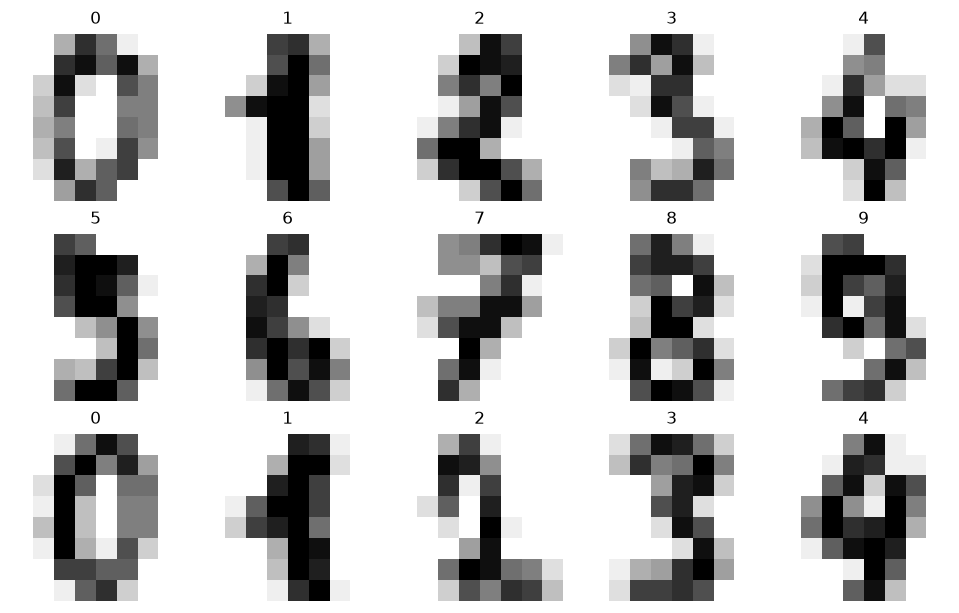

In [15]:
def display_digits(imgs):
    _, ax = plt.subplots(3, 5, figsize=(8, 5), layout='constrained')
    for i, a in enumerate(ax.flat):
        a.imshow(imgs[i].reshape(8, 8), cmap='gray_r', vmin=0, vmax=16)
        a.set_title(str(data_digit.target[i]), fontsize=10)
        a.axis('off')

display_digits(data_digit.images)

**PCA** finds uncorrelated orthogonal axes (principal components) in a high dimensional space (i.e., 64) to project the feature onto principal components.

## Question 3.1 (PCA and dimensionality deduction with Scikit-learn, 10 pts)

In this question, you may use the implementation of PCA from scikit-learn, as imported below. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Fit the model with feature X (**data_digit.data** for this dataset) and apply the dimensionality reduction on X, keep 2 components.

In [16]:
from sklearn.decomposition import PCA
p2 = PCA(2, svd_solver='full')
projected = p2.fit_transform(x)
print(x.shape, projected.shape)

(1797, 64) (1797, 2)


With the reduced dimension of features, we can now visualize the projected/reduced features in a 2-dimension plot as below. There are hardly any overlaps between digit 0 and any other digits. While in the central area of the figure, features are not well separable.

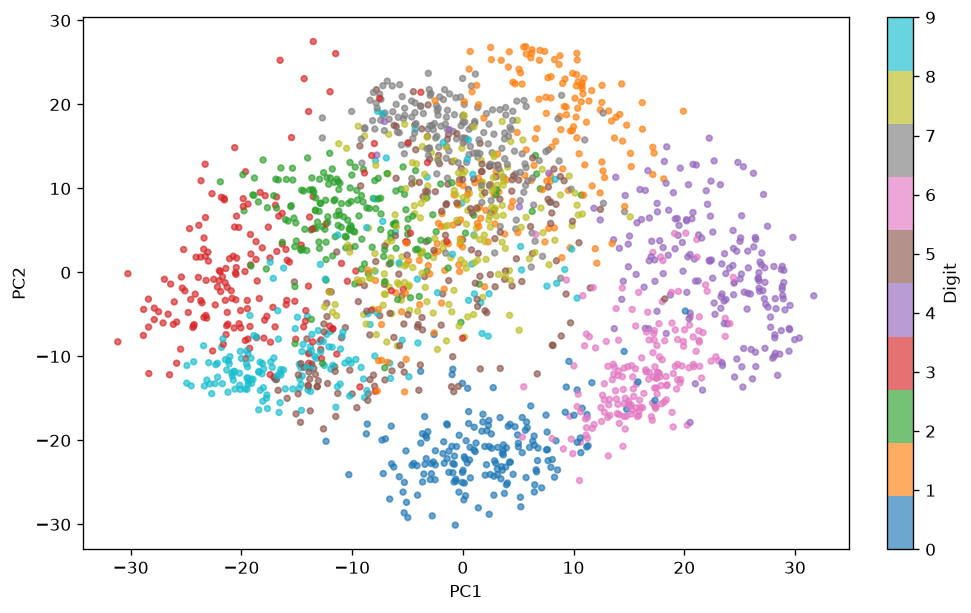

In [17]:
plt.figure(figsize=(8, 5), layout='constrained')
s = plt.scatter(projected[:, 0], projected[:, 1], c=data_digit.target,
                s=12, alpha=.65, cmap=plt.get_cmap('tab10', 10))
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(s, ticks=range(10), label='Digit')
plt.show()

## Question 3.2 (How many components do we need? 15 pts)

In practice, suppose you are given a high-dimension dataset, and you are interested in performing a dimension reduciton with PCA. How many conponents do we need? One method is to look at the distribution of the explained variance ratio w.r.t. each component.

In this question, you may use the function <code>explained_variance_ratio</code> in **pca** (with scikit-learn) to address this question. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Print the ratio of variance explained by each of the selected components;

Visualize with matplotlib or seaborn (x axis: $i-th$ component; y axis: the corresponding ratio of explained variance).

2 PCs: [0.1489 0.1362]
[1.489e-01 1.362e-01 1.179e-01 8.410e-02 5.780e-02 4.920e-02 4.320e-02
 3.660e-02 3.350e-02 3.080e-02 2.370e-02 2.270e-02 1.820e-02 1.770e-02
 1.470e-02 1.410e-02 1.320e-02 1.250e-02 1.020e-02 9.100e-03 8.900e-03
 8.000e-03 7.700e-03 7.200e-03 7.000e-03 6.000e-03 5.800e-03 5.200e-03
 4.900e-03 4.300e-03 3.700e-03 3.500e-03 3.400e-03 3.300e-03 3.100e-03
 2.900e-03 2.600e-03 2.300e-03 2.200e-03 2.100e-03 1.900e-03 1.600e-03
 1.500e-03 1.400e-03 1.200e-03 1.100e-03 1.000e-03 8.000e-04 6.000e-04
 4.000e-04 2.000e-04 1.000e-04 1.000e-04 1.000e-04 0.000e+00 0.000e+00
 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00
 0.000e+00]
80%: 13


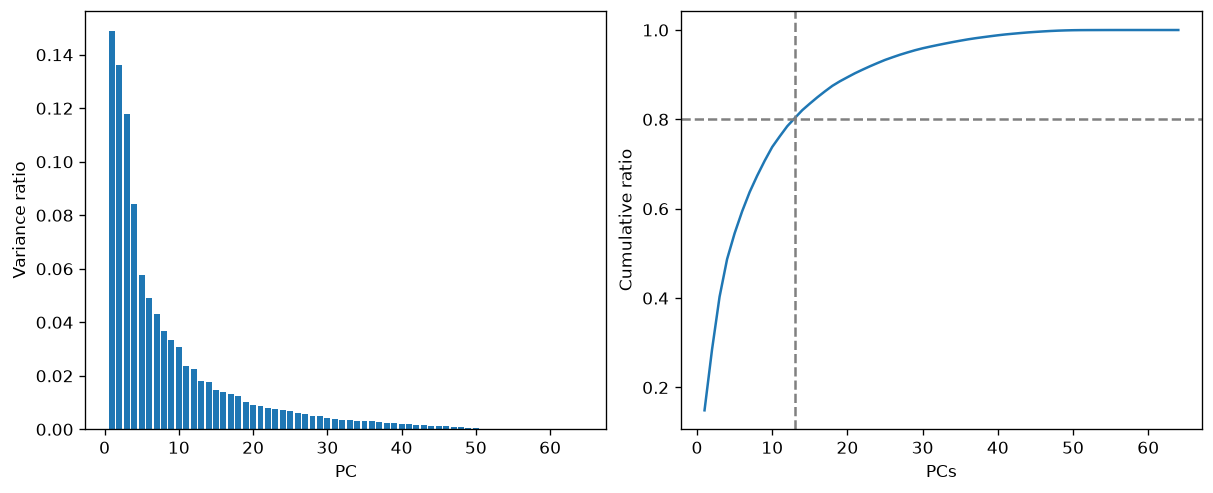

In [18]:
print('2 PCs:', p2.explained_variance_ratio_.round(4))
pca = PCA(svd_solver='full').fit(x)
v = pca.explained_variance_ratio_
k = np.searchsorted(v.cumsum(), .8) + 1
print(v.round(4))
print('80%:', k)
_, ax = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
t = np.arange(1, 65)
ax[0].bar(t, v)
ax[0].set(xlabel='PC', ylabel='Variance ratio')
ax[1].plot(t, v.cumsum())
ax[1].axhline(.8, ls='--', c='gray')
ax[1].axvline(k, ls='--', c='gray')
ax[1].set(xlabel='PCs', ylabel='Cumulative ratio')
plt.show()

### How to obtain eigen values and vectors from sklearn PCA

- Eigen values -- <code>your-PCA-model\.explained\_variance\_</code>

- Eigen vectors -- <code>your-PCA-model.components_ </code>

### Eigen vectors (Eigen digits)

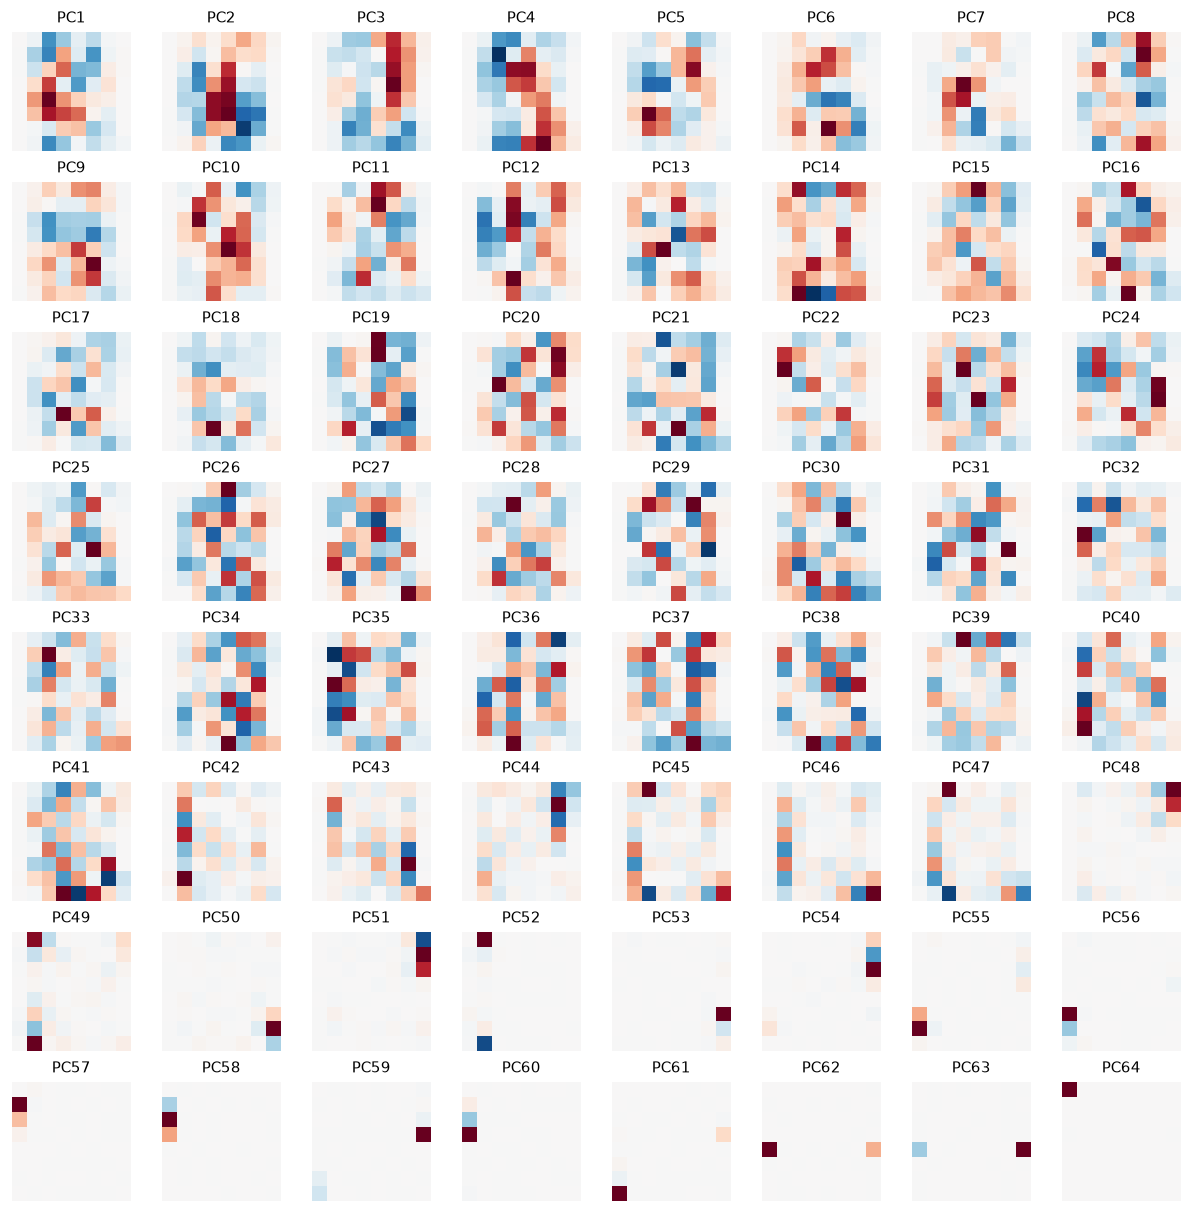

In [19]:
_, ax = plt.subplots(8, 8, figsize=(10, 10), layout='constrained')
for i, a in enumerate(ax.flat):
    z = pca.components_[i].reshape(8, 8)
    t = abs(z).max()
    a.imshow(z, cmap='RdBu_r', vmin=-t, vmax=t)
    a.set_title(f'PC{i+1}', fontsize=9)
    a.axis('off')
plt.show()

## Question 3.3 What are your observations from the visualized eigen vectors? (5 pts)

early PCs: broad strokes. later PCs: finer details.

### Feature reconstruction:

Suppose you only want to preserve $80\%$ variance after applying PCA for the dimension reduction, due to storage issues, etc. 

13 0.8028957761040317


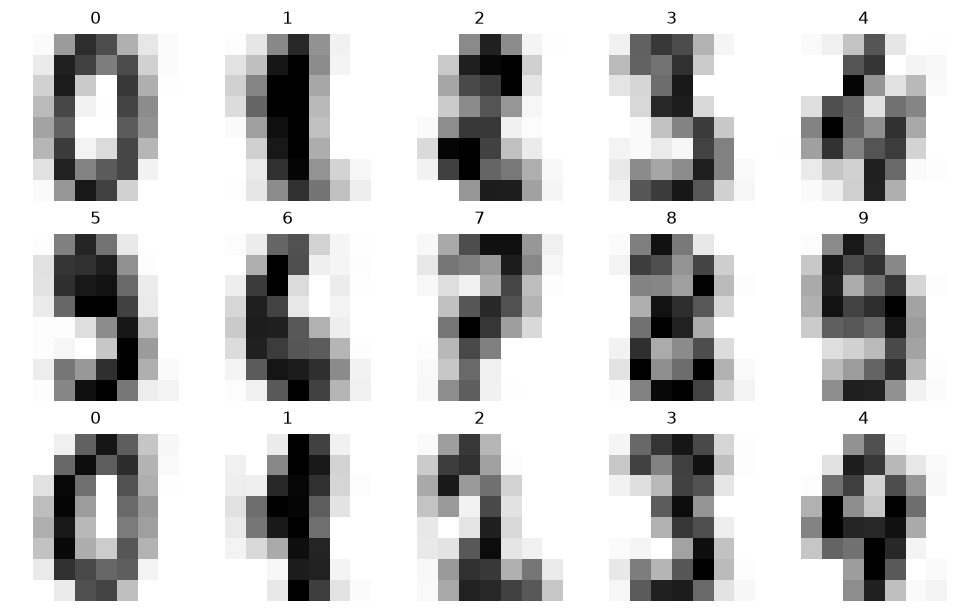

In [20]:
pca_08 = PCA(.8, svd_solver='full')
lower_dimension = pca_08.fit_transform(x)
reconstructed = pca_08.inverse_transform(lower_dimension)
print(pca_08.n_components_, pca_08.explained_variance_ratio_.sum())
display_digits(reconstructed)

Assume now you are given only a set of perturbed images (with some random noise). As shown below, the figures become much more difficult to recognize.

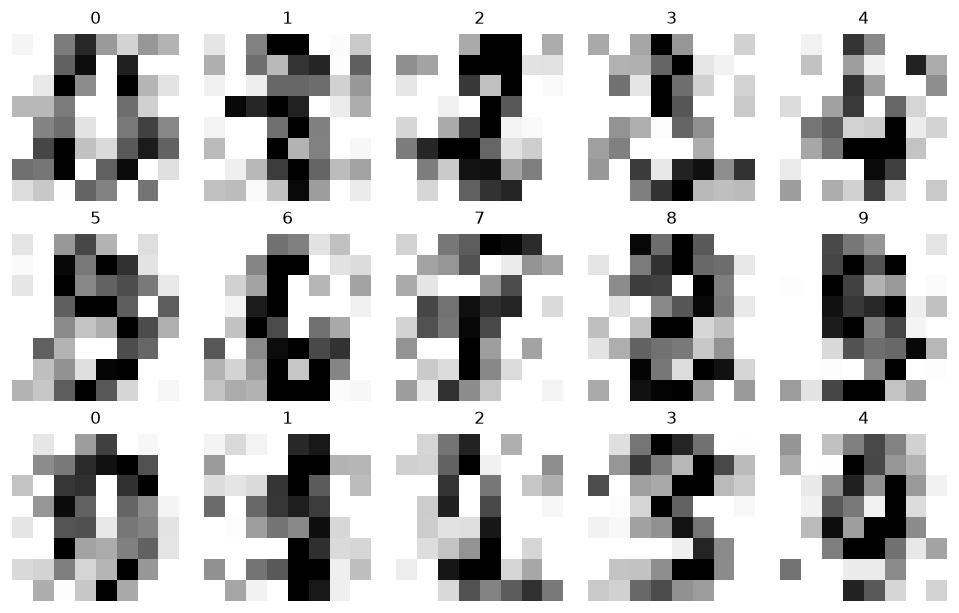

In [21]:
noisy_imgs = np.random.default_rng(0).normal(x, 5)
display_digits(noisy_imgs)

## Question 3.4 Does PCA mitigate the random noise? (10 pts)

### Your tasks:

- Perform feature reconstruction on <code>noisy\_imgs</code> (preserving $80\%$ variance after applying PCA for the dimension reduction)

- Explain your understandings on why PCA reconstructs cleaner images.

40 0.8003675604187769
25.018191523675448 17.490983126138936


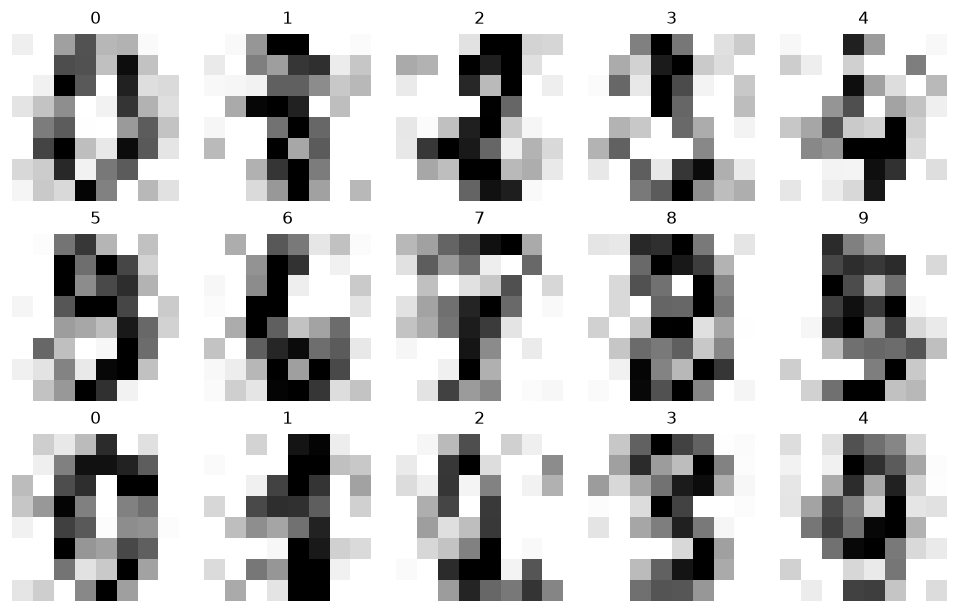

In [22]:
pn = PCA(.8, svd_solver='full')
z = pn.fit_transform(noisy_imgs)
reconstructed_noise = pn.inverse_transform(z)
print(pn.n_components_, pn.explained_variance_ratio_.sum())
print(mse(x, noisy_imgs), mse(x, reconstructed_noise))
display_digits(reconstructed_noise)

40 PCs; MSE 25.02 → 17.49. dropping weaker directions removes some noise, but loses detail too.